## 1. Package Setup

This section imports all the Python libraries and tools needed throughout this project.

In [373]:
# Data analysis and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
from itertools import combinations
from tqdm.auto import tqdm

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from mlxtend.feature_selection import ExhaustiveFeatureSelector
from sklearn.model_selection import StratifiedKFold



# Preprocessing and feature selection
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

# Model evaluation and tuning
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, cross_val_score, GridSearchCV


## 2. Data Loading & Inspection

We begin by inspecting the dataset to check for missing values, incorrect labels, and values outside the expected range. We also examine the basic structure and characteristics of the data before further analysis.

In [374]:
# load and inspect dataset
df = pd.read_csv("data/ACME-HappinessSurvey2020.csv")

# display top 5 rows of the dataframe
display(df.head())

# display number of column and rows
print("Shape:", df.shape)

# check if there are any missing values
df.info() 

# display unique values for target and features
print("Y:", df["Y"].unique())
for col in ["X1", "X2", "X3", "X4", "X5", "X6"]:
    print(col, np.sort(df[col].unique())) 

# check target class distribution
print(df["Y"].value_counts())
print(df["Y"].value_counts(normalize=True))


,Y,X1,X2,X3,X4,X5,X6
0,0,3,3,3,4,2,4
1,0,3,2,3,5,4,3
2,1,5,3,3,3,3,5
3,0,5,4,3,3,3,5
4,0,5,4,3,3,3,5


Shape: (126, 7)
<class 'pandas.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Y       126 non-null    int64
 1   X1      126 non-null    int64
 2   X2      126 non-null    int64
 3   X3      126 non-null    int64
 4   X4      126 non-null    int64
 5   X5      126 non-null    int64
 6   X6      126 non-null    int64
dtypes: int64(7)
memory usage: 7.0 KB
Y: [0 1]
X1 [1 3 4 5]
X2 [1 2 3 4 5]
X3 [1 2 3 4 5]
X4 [1 2 3 4 5]
X5 [1 2 3 4 5]
X6 [1 2 3 4 5]
Y
1    69
0    57
Name: count, dtype: int64
Y
1    0.547619
0    0.452381
Name: proportion, dtype: float64


Result shows that there is no missing value across the csv. Also, all data points belong to their expected range.

## 3. Exploratory Data Analysis

In this section, we create bar charts to visualize the distribution of each feature. This helps us identify unusual patterns or potential anomalies that may require further investigation.

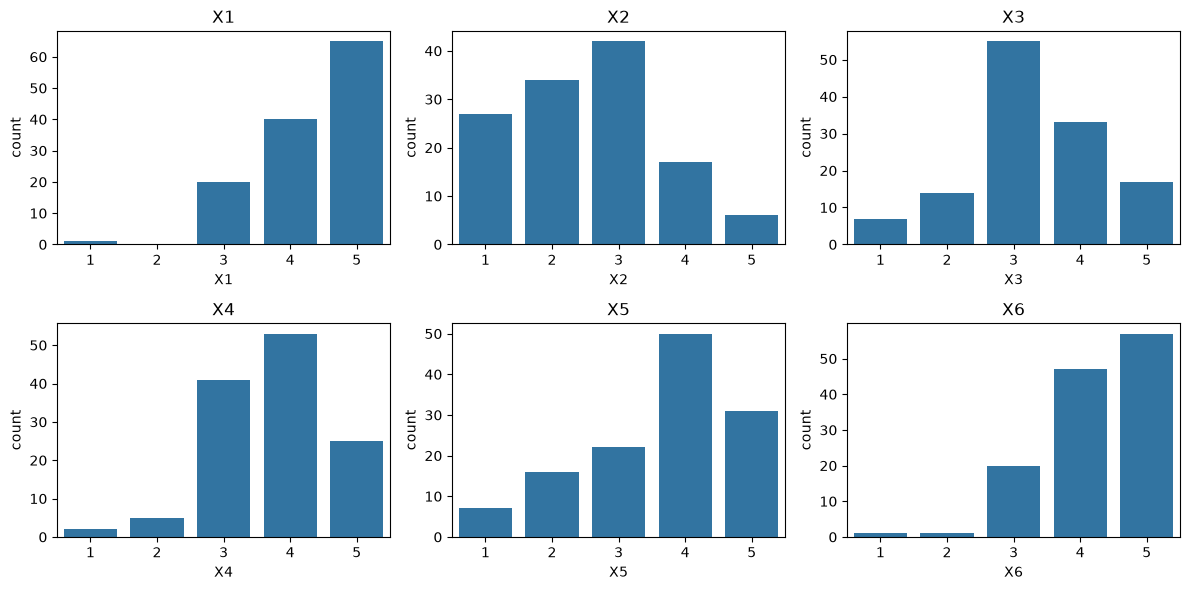

In [375]:
# Plot rating distributions for X1-X6
features = ["X1", "X2", "X3", "X4", "X5", "X6"]

plt.figure(figsize=(12, 6))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    sns.countplot(data=df, x=features[i], order=[1, 2, 3, 4, 5])
    plt.title(features[i])

plt.tight_layout()
plt.show()

Result shows that X1 and X6 are skewed toward high ratings 4 and 5.
X2 and X3 have more balnaced distribution, with ratings concentrated around 3.
X4 and X5 are skewed toward higher ratings, namely 4.
No invalid values or data quality issues were obsereved.

## 4. Repeated Stratified 5-Fold Cross-Validation

Because our dataset is relatively small, with only 126 records, splitting it into separate training and testing sets would leave limited data for model training and evaluation.

Therefore, we will use Repeated Stratified 5-Fold Cross-Validation. The dataset is divided into five folds, with each fold used once as the validation set (20%), while the remaining four folds (80%) are used for training. Stratification ensures that each fold maintains approximately the same class distribution as the original dataset.

To reduce the influence of random data splitting, we repeat this process five times with different splits, resulting in 25 training-validation splits in total.

In [376]:
# Separate features (X) and target (y)
X = df[["X1", "X2", "X3", "X4", "X5", "X6"]]
y = df["Y"]

# Create repeated stratified 5-fold cross-validation
# Keep class ratios similar, repeat 5 times, and fix randomness
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=1
)

# Generate and save all 25 training/validation splits
folds = list(cv.split(X, y))

print("Total splits:", len(folds))

# Get training and validation indices from the first split
train_index, valid_index = folds[0]

# Check the number of samples in each group
print("Training samples:", len(train_index))
print("Validation samples:", len(valid_index))


Total splits: 25
Training samples: 100
Validation samples: 26


## 5. Default Model Evaluation

In this section, we evaluate several machine learning models using their default hyperparameters. The goal is to establish their baseline performance, which we can later compare with the results of feature selection and hyperparameter tuning.

### 5.1 Dummy Classifier 

Always predicts the most frequent class. Used as a basic baseline model.

In [377]:
# Store model evaluation results
model_results = {}

# Evaluate models using the same 25 CV splits
def evaluate(name, classifier):
    scores = cross_validate(
        classifier, X, y,
        cv=folds,
        scoring=["accuracy", "balanced_accuracy", "f1_macro"],
        return_train_score=True
    )

    train_acc = scores["train_accuracy"].mean()
    valid_acc = scores["test_accuracy"].mean()

    model_results[name] = {
        "Train Accuracy": train_acc,
        "Validation Accuracy": valid_acc,
        "Gap": train_acc - valid_acc,
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "F1 Macro": scores["test_f1_macro"].mean()
    }

    print("Train Accuracy:", train_acc)
    print("Validation Accuracy:", valid_acc)
    print("Gap:", train_acc - valid_acc)


In [378]:
# Create a baseline model that always predicts the majority class
dummy = DummyClassifier(strategy="most_frequent")

evaluate("Dummy Classifier", dummy)

Train Accuracy: 0.5476237623762377
Validation Accuracy: 0.5476923076923077
Gap: -6.854531607003445e-05


### 5.2 Logistic Regression

Uses a linear combination of features to estimate class probabilities.

In [379]:
# Scale features and create the Logistic Regression model
logistic_regression = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000)
)

evaluate("Logistic Regression", logistic_regression)

Train Accuracy: 0.6012000000000001
Validation Accuracy: 0.5493538461538462
Gap: 0.051846153846153875


### 5.3 Decision Tree

Splits data into groups based on feature values to make predictions.

In [380]:
# Create a Decision Tree model with default parameters
decision_tree = DecisionTreeClassifier(random_state=1)

evaluate("Decision Tree", decision_tree)


Train Accuracy: 0.9512
Validation Accuracy: 0.5539076923076923
Gap: 0.3972923076923077


### 5.4 Random Forest

Combines predictions from multiple decision trees to improve stability.

In [381]:
# Create a Random Forest model with default parameters
random_forest = RandomForestClassifier(random_state=1)

evaluate("Random Forest", random_forest)

Train Accuracy: 0.9512
Validation Accuracy: 0.5715076923076923
Gap: 0.3796923076923078


### 5.5 Support Vector Machine

Finds a decision boundary that separates classes, potentially using a nonlinear kernel.

In [382]:
# Scale features and create the SVM model
svm = make_pipeline(
    StandardScaler(),
    SVC()
)

evaluate("SVM", svm)

Train Accuracy: 0.7777742574257425
Validation Accuracy: 0.547876923076923
Gap: 0.22989733434881943


### 5.6 Gradient Boosting Classifier

Builds trees sequentially, with each stage improving the previous predictions.

In [383]:
# Create a Gradient Boosting model with default parameters
gradient_boosting = GradientBoostingClassifier(random_state=1)

evaluate("Gradient Boosting", gradient_boosting)

Train Accuracy: 0.9123089108910891
Validation Accuracy: 0.5985230769230769
Gap: 0.3137858339680122


### 5.7 K-Nearest Neighbors

Predicts a class based on the nearest training samples.

In [384]:
# Scale features and create the KNN model
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

evaluate("KNN", knn)

Train Accuracy: 0.707160396039604
Validation Accuracy: 0.5223384615384615
Gap: 0.18482193450114248


### 5.8 Naive Bayes

Uses probability and assumes features are conditionally independent given the class.

In [385]:
# Convert ratings from 1-5 to 0-4
def encode_ratings(X):
    return X - 1

# Create Categorical Naive Bayes pipeline
naive_bayes = make_pipeline(
    FunctionTransformer(encode_ratings),
    CategoricalNB(min_categories=5)
)

evaluate("Naive Bayes", naive_bayes)

Train Accuracy: 0.6817623762376237
Validation Accuracy: 0.5701538461538462
Gap: 0.11160853008377747


### 5.9 Model Comparison

We compare the initial performance of all models using their default hyperparameters and identify the best-performing models for further analysis.

In [386]:
# Compare all eight models and sort by Accuracy
comparison = pd.DataFrame(model_results).T
comparison = comparison.sort_values("Validation Accuracy", ascending=False)

# Highlight the Dummy Classifier in red
def highlight_dummy(row):
    if row.name == "Dummy Classifier":
        return ["color: red; font-weight: bold"] * len(row)
    return [""] * len(row)

# Display scores as percentages with two decimal places
display(
    comparison.style
    .format("{:.2%}")
    .apply(highlight_dummy, axis=1)
    .map_index(
        lambda name: "color: red; font-weight: bold"
        if name == "Dummy Classifier" else "",
        axis=0
    )
)

,Train Accuracy,Validation Accuracy,Gap,Balanced Accuracy,F1 Macro
Gradient Boosting,91.23%,59.85%,31.38%,59.15%,58.83%
Random Forest,95.12%,57.15%,37.97%,56.38%,55.92%
Naive Bayes,68.18%,57.02%,11.16%,56.11%,55.67%
Decision Tree,95.12%,55.39%,39.73%,55.22%,54.75%
Logistic Regression,60.12%,54.94%,5.18%,53.67%,52.79%
SVM,77.78%,54.79%,22.99%,53.80%,52.61%
Dummy Classifier,54.76%,54.77%,-0.01%,50.00%,35.38%
KNN,70.72%,52.23%,18.48%,51.00%,50.26%


The initial results show that all models have relatively low validation accuracy. Gradient Boosting, Random Forest, and Naive Bayes are the three best-performing models, but none achieves a validation accuracy above 60%. Even the best model, Gradient Boosting, only improves accuracy by about 5 percentage points compared with the Dummy Classifier.

However, the F1 Macro scores show a more noticeable improvement over the Dummy Classifier. This suggests that these models are better at balancing precision and recall across both classes, rather than simply predicting the majority class.

In addition, several models show signs of overfitting. Decision Tree, Random Forest, and Gradient Boosting have training-validation gaps exceeding 30 percentage points. SVM and KNN also show relatively large gaps of around 20 percentage points.

Further feature selection and hyperparameter tuning may help improve validation accuracy and reduce overfitting.

## 6. Feature Selection

We will proceed with feature selection, as suggested by the client. The goal is to answer an important question: What is the smallest set of features that can preserve the most useful information for predicting customer happiness?

By removing less relevant or redundant features, we aim to reduce the number of survey questions while maintaining or potentially improving prediction accuracy.

### 6.1 Filter Method

The Filter Method selects features based on their statistical relationship with the target, without training a prediction model.

We use SelectKBest with two scoring methods:
- ANOVA F-test: Meausres the difference in feature ratings between happy and unhappy customers, relative to variation within each group.
- Mutual Information(MI): Measures how much information each feature provides about customer happiness.

We will examine the feature rankding produced by both methods and evaluate whether selecting the top-ranked features improves the performance of our existing classification models in Section 7.

In [387]:
# Calculate feature scores
anova_scores = f_classif(X, y)[0]
mi_scores = mutual_info_classif(
    X, y, discrete_features=True, random_state=1
)

# Display feature rankings
display(pd.Series(anova_scores, index=X.columns, name="ANOVA")
        .sort_values(ascending=False).to_frame())

display(pd.Series(mi_scores, index=X.columns, name="MI")
        .sort_values(ascending=False).to_frame())


,ANOVA
X1,10.561708
X5,6.582716
X6,3.586849
X3,2.886959
X4,0.516657
X2,0.073108


,MI
X1,0.049705
X6,0.035543
X5,0.027627
X4,0.021880
X3,0.017432
X2,0.009468


Initial results show that both ANOVA and Mutual Information rank X1 as the most informative feature and X2 as the least informative feature. Although X5 and X6 have different rankings, both methods select the same top three features: X1, X5 and X6.

Next, we will use both filter methods to select the top 1 to 6 features for each of the seven classification models. This gives us 84 configurations in total. Each configuration will be evaluated using the same 25 cross-validation splits. We will compare their training accuracy, validation accuracy, balanced accuracy, and F1 Macro, and identify the best number of features for each model and selection method.

In [388]:
# Reuse models from Section 5
classifiers = {
    "Logistic Regression": logistic_regression,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "SVM": svm,
    "Gradient Boosting": gradient_boosting,
    "KNN": knn,
    "Naive Bayes": naive_bayes
}

# Calculate Mutual Information for discrete ratings
def mi_score(X, y):
    return mutual_info_classif(
        X, y, discrete_features=True, random_state=1
    )

filter_methods = {
    "ANOVA": f_classif,
    "MI": mi_score
}

# Evaluate each model, method, and number of features
filter_results = []

with tqdm(total=len(classifiers) * len(filter_methods) * 6) as progress:
    for name, classifier in classifiers.items():
        for method, score_func in filter_methods.items():
            for k in range(1, 7):

                pipeline = make_pipeline(
                    SelectKBest(score_func=score_func, k=k),
                    classifier
                )

                scores = cross_validate(
                    pipeline, X, y,
                    cv=folds,
                    scoring=["accuracy", "balanced_accuracy", "f1_macro"],
                    return_train_score=True
                )

                train_acc = scores["train_accuracy"].mean()
                valid_acc = scores["test_accuracy"].mean()

                filter_results.append({
                    "Model": name,
                    "Method": method,
                    "Features": k,
                    "Train Accuracy": train_acc,
                    "Validation Accuracy": valid_acc,
                    "Gap": train_acc - valid_acc,
                    "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
                    "F1 Macro": scores["test_f1_macro"].mean()
                })

                progress.update(1)

filter_results = pd.DataFrame(filter_results)

# Find the best configuration for each model and method
best_filter = filter_results.loc[
    filter_results.groupby(["Model", "Method"])["Validation Accuracy"].idxmax()
].sort_values("Validation Accuracy", ascending=False)

# Display results
metric_cols = [
    "Train Accuracy", "Validation Accuracy", "Gap",
    "Balanced Accuracy", "F1 Macro"
]

display(
    best_filter.style
    .format("{:.2%}", subset=metric_cols)
    .hide(axis="index")
)


  0%|          | 0/84 [00:00<?, ?it/s]

Model,Method,Features,Train Accuracy,Validation Accuracy,Gap,Balanced Accuracy,F1 Macro
Gradient Boosting,ANOVA,4,84.37%,63.79%,20.58%,63.05%,62.91%
KNN,ANOVA,4,76.23%,63.35%,12.88%,62.61%,62.32%
Decision Tree,ANOVA,2,71.87%,63.19%,8.68%,62.52%,62.03%
KNN,MI,3,72.70%,63.19%,9.51%,62.39%,61.87%
Decision Tree,MI,3,77.90%,63.02%,14.88%,62.27%,61.58%
Gradient Boosting,MI,3,77.78%,63.02%,14.76%,61.66%,60.81%
Random Forest,ANOVA,2,71.87%,62.88%,8.99%,61.70%,60.82%
Random Forest,MI,3,77.90%,62.41%,15.49%,61.42%,60.61%
SVM,ANOVA,1,65.04%,60.95%,4.09%,60.39%,59.75%
Logistic Regression,ANOVA,1,64.05%,60.66%,3.39%,60.08%,58.84%


### 6.2 Wrapper Method

The Wrapper Method selects features by testing different feature combinations with a machine learning model, rather than ranking each feature individually.

Since our dataset contains only six features, Exhaustive Feature Selection is feasible. We will test all 63 non-empty feature combinations for each of the seven classification models.

Each combination will be evaluated using the same 25 cross-validation splits. We will calculate training accuracy, validation accuracy, balanced accuracy, and F1 Macro. The combination with the highest average validation accuracy will be selected for each model.

In [389]:
# Define 5-fold cross-validation for feature selection
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Create an Exhaustive Feature Selector
def make_wrapper_selector(classifier):
    return ExhaustiveFeatureSelector(
        estimator=classifier,
        min_features=1,
        max_features=6,
        scoring="accuracy",
        cv=inner_cv,
        print_progress=False,
        n_jobs=1
    )

In [390]:
# Store results for all feature combinations
wrapper_results = []

for name, classifier in classifiers.items():

    # Evaluate all 63 combinations for each model
    with tqdm(total=63) as progress:

        for k in range(1, 7):
            for features in combinations(X.columns, k):

                scores = cross_validate(
                    classifier, X[list(features)], y,
                    cv=folds,
                    scoring=["accuracy", "balanced_accuracy", "f1_macro"],
                    return_train_score=True
                )

                train_acc = scores["train_accuracy"].mean()
                valid_acc = scores["test_accuracy"].mean()

                wrapper_results.append({
                    "Model": name,
                    "Features": ", ".join(features),
                    "Train Accuracy": train_acc,
                    "Validation Accuracy": valid_acc,
                    "Gap": train_acc - valid_acc,
                    "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
                    "F1 Macro": scores["test_f1_macro"].mean()
                })

                progress.update(1)

wrapper_results = pd.DataFrame(wrapper_results)


  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

In [391]:
# Find the best feature combination for each model
wrapper_summary = wrapper_results.loc[
    wrapper_results.groupby("Model")["Validation Accuracy"].idxmax()
]

wrapper_summary = wrapper_summary.sort_values(
    "Validation Accuracy", ascending=False
)

# Display results
display(
    wrapper_summary.style
    .format({
        "Train Accuracy": "{:.2%}",
        "Validation Accuracy": "{:.2%}",
        "Gap": "{:.2%}",
        "Balanced Accuracy": "{:.2%}",
        "F1 Macro": "{:.2%}"
    })
    .hide(axis="index")
)

Model,Features,Train Accuracy,Validation Accuracy,Gap,Balanced Accuracy,F1 Macro
Decision Tree,"X1, X3, X6",80.52%,70.79%,9.73%,69.91%,69.76%
Gradient Boosting,"X1, X3, X6",80.40%,69.82%,10.58%,68.65%,68.32%
KNN,"X1, X3, X6",74.33%,69.39%,4.94%,68.72%,68.61%
Random Forest,"X1, X3, X6",80.52%,69.06%,11.45%,68.14%,67.72%
SVM,X1,65.12%,64.31%,0.81%,64.05%,63.65%
Naive Bayes,X1,65.12%,63.51%,1.61%,63.16%,62.81%
Logistic Regression,X1,64.01%,63.06%,0.95%,62.37%,61.00%


### 6.3 Feature Selection Summary
Filter Selection improved validation accuracy from below 60% to 63.79%, achieved by Gradient Boosting using ANOVA with four features: X1, X3, X5, and X6. KNN also performed well with the same features.

Exhaustive Selection achieved a higher validation accuracy of 70.79% using Decision Tree with only three features: X1, X3, and X6. This combination also performed well with other models, suggesting that fewer features may improve prediction accuracy.

Overall, Feature Selection improved performance while reducing the number of survey questions from six to three. However, the results may vary with different data splits.

Next, we will tune the four best-performing models to further improve their performance and reduce potential overfitting.

## 7. Hyperparameter Tuning

We will tune the hyperparameters of the four best-performing models from Exhaustive Feature Selection: Decision Tree, Gradient Boosting, KNN, and Random Forest. We will use the selected features X1, X3, and X6 and the same 25 cross-validation splits to compare different hyperparameter settings, aiming to improve validation accuracy and reduce potential overfitting.

We define a shared function tune_model() to tune all four models consistently.

1. Baseline: Retrieve the best result from Exhaustive Feature Selection in Section 6.
2. Individual Grid Search: Test each hyperparameter separately while keeping the others at their default values. Keep the two best-performing values for each parameter.
3. Combined Search: Test combinations of the selected values, including default settings and configurations where only one parameter changes.
4. Results: Save all tested configurations and summarize the best validation accuracy from each stage.

All configurations are evaluated using the same 25 cross-validation splits. Validation accuracy is used to select the best parameters, while the other metrics help us compare model performance and potential overfitting.

In [392]:
# Shared settings
X_selected = X[["X1", "X3", "X6"]]
scoring = ["accuracy", "balanced_accuracy", "f1_macro"]

def tune_model(name, model, grids):

    # Get baseline from Section 6
    baseline = wrapper_summary.loc[
        wrapper_summary["Model"] == name
    ].iloc[0]

    results = [{
        "Stage": "Baseline",
        "Parameter": "Default",
        "Value": "-",
        "Train Accuracy": baseline["Train Accuracy"],
        "Validation Accuracy": baseline["Validation Accuracy"],
        "Gap": baseline["Gap"],
        "Balanced Accuracy": baseline["Balanced Accuracy"],
        "F1 Macro": baseline["F1 Macro"]
    }]

    # Run Grid Search using the same CV splits
    def grid_search(params):
        search = GridSearchCV(
            model, params,
            cv=folds,
            scoring=scoring,
            refit="accuracy",
            return_train_score=True,
            n_jobs=1
        )
        search.fit(X_selected, y)
        return search

    # Save all tested configurations
    def save_results(search, stage, parameter):
        scores = search.cv_results_

        for i, params in enumerate(scores["params"]):
            train_acc = scores["mean_train_accuracy"][i]
            valid_acc = scores["mean_test_accuracy"][i]

            results.append({
                "Stage": stage,
                "Parameter": parameter,
                "Value": str(params[parameter]) if stage == "Individual" else str(params),
                "Train Accuracy": train_acc,
                "Validation Accuracy": valid_acc,
                "Gap": train_acc - valid_acc,
                "Balanced Accuracy": scores["mean_test_balanced_accuracy"][i],
                "F1 Macro": scores["mean_test_f1_macro"][i]
            })

    # Test each parameter individually
    best_values = {}

    for param, values in grids.items():
        search = grid_search({param: values})
        save_results(search, "Individual", param)

        scores = search.cv_results_
        ranking = scores["mean_test_accuracy"].argsort()[::-1]

        best_values[param] = [
            scores["params"][i][param] for i in ranking[:2]
        ]

        print(param, search.best_params_[param],
              format(search.best_score_, ".2%"))

    # Combine selected values and defaults
    defaults = {
        param: [model.get_params()[param]] for param in grids
    }

    combined_grids = [best_values, defaults]

    for param in grids:
        config = defaults.copy()
        config[param] = best_values[param]
        combined_grids.append(config)

    # Run combined Grid Search
    combined = grid_search(combined_grids)
    save_results(combined, "Combined", "All")

    # Save the best result from each stage
    results = pd.DataFrame(results)

    summary = results.loc[
        results.groupby("Stage", sort=False)["Validation Accuracy"].idxmax()
    ]

    print("Tuned:", format(combined.best_score_, ".2%"),
          combined.best_params_)

    # Display baseline vs tuned
    columns = [
        "Train Accuracy", "Validation Accuracy", "Gap",
        "Balanced Accuracy", "F1 Macro"
    ]

    comparison = summary[
        summary["Stage"].isin(["Baseline", "Combined"])
    ].copy()

    comparison["Stage"] = comparison["Stage"].replace({
        "Combined": "Tuned"
    })

    comparison = comparison.rename(columns={
        "Stage": "Configuration"
    })

    display(
        comparison[["Configuration"] + columns]
        .style.format("{:.2%}", subset=columns)
        .hide(axis="index")
    )

    return results, summary, combined

### 7.1 Decision Tree Tuning

We start with the top performing model first, the Decision Tree. Decision Tree achieved a validation accuracy of 70.79% using X1, X3, and X6, with a training-validation gap of 9.73%. We will tune the following hyperparameters to improve validation accuracy and control potential overfitting.

Parameters:

1. criterion:*Default(gini), criterterion measures the quality of a split. "gini" uses Gini impurity, while "entropy" uses information gain. Neigher is always better.
2. max_depth: Default (None), the maximum depth of the tree. Higher values allow more complex tress and may increase overfitting. Lower values creater simpler trees.
3. min_samples_leaf: Default (1), minimum samples required in each leaf. Higher values prevent very small leaves and can reduce overfitting.
4. min_samples_split: Default (2), minimum samples required to split a node. Higher values restrict splitting and generally produce simpler trees.
5. max_features: Default (None), number of features considered at each split. Lowever values introduce more randomness, while None considers all available features.

In [393]:
# Decision Tree parameter grid
dt_grids = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 7, 8, None],
    "min_samples_split": [2, 3, 5, 10, 20],
    "min_samples_leaf": [1, 2, 3, 5, 10],
    "max_features": [None, 1, 2]
}

# Run Grid Search and display results
dt_results, dt_summary, dt_search = tune_model(
    "Decision Tree", decision_tree, dt_grids
)

criterion gini 70.79%
max_depth None 70.79%
min_samples_split 2 70.79%
min_samples_leaf 1 70.79%
max_features None 70.79%
Tuned: 70.79% {'criterion': 'gini', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2}


Configuration,Train Accuracy,Validation Accuracy,Gap,Balanced Accuracy,F1 Macro
Baseline,80.52%,70.79%,9.73%,69.91%,69.76%
Tuned,80.52%,70.79%,9.73%,69.91%,69.76%


Results indicate the the Decision Tree achieved its highest validation accuracy of 70.79% with the default hyperparameters. The tested restriction on tree complexity did not improve performance and often reduced validation accuracy. Therfore, we retain the default configuration for model comparison.

### 7.2 Gradient Boosting Tuning

Next, we will tune Gradient Boosting, which achieved a validation accuracy of 69.82% using X1, X3, and X6, with a training-validation gap of 10.58%.

Parameters:

1. n_estimators:*Default (100), the number of trees used in boosting. Higher values allow the model to learn more patterns but may increase overfitting and training time.
2. learning_rate: Default (0.1), controls how much each tree contributes to the model. Lower values make smaller adjustments and usually require more trees.
3. *ax_depth:*Default (3), the maximum depth of each tree. Higher values allow more complex trees and may increase overfitting. Lower values create simpler trees.
4. min_samples_split:*Default (2), minimum samples required to split a node. Higher values restrict splitting and generally produce simpler trees.
5. *in_samples_leaf: Default (1), minimum samples required in each leaf. Higher values prevent very small leaves and may reduce overfitting.
6. subsample:*Default (1.0), the fraction of training samples used for each tree. Lower values introduce randomness and may help reduce overfitting.

In [394]:
# Gradient Boosting parameter grid
gb_grids = {
    "n_estimators": [50, 100, 150, 200],
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "max_depth": [1, 2, 3, 4],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "subsample": [0.7, 0.85, 1.0]
}

# Run individual and combined Grid Search
gb_results, gb_summary, gb_search = tune_model(
    "Gradient Boosting", gradient_boosting, gb_grids
)

n_estimators 100 69.82%
learning_rate 0.1 69.82%
max_depth 3 69.82%
min_samples_split 10 70.15%
min_samples_leaf 1 69.82%
subsample 0.85 69.83%
Tuned: 71.27% {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200, 'subsample': 1.0}


Configuration,Train Accuracy,Validation Accuracy,Gap,Balanced Accuracy,F1 Macro
Baseline,80.40%,69.82%,10.58%,68.65%,68.32%
Tuned,79.72%,71.27%,8.45%,70.39%,70.25%


### 7.3 KNN Tuning

Next, we will tune KNN, which achieved a validation accuracy of 69.39% using X1, X3, and X6, with a training-validation gap of 4.94%. 

Parameters:

1. n_neighbors: Default (5), the number of nearest neighbors used to make predictions. Lower values make the model more sensitive to individual samples and may increase overfitting. Higher values produce smoother predictions but may cause underfitting.
2. weights: Default ("uniform"), controls how neighbors contribute to predictions. "uniform" gives equal weight to all neighbors, while "distance" gives more weight to closer neighbors.
3. p: Default (2), controls how distance is calculated. p=1 uses Manhattan distance, while p=2 uses Euclidean distance. Higher values place more emphasis on larger differences between features.

In [395]:
# KNN parameter grid
knn_grids = {
    "kneighborsclassifier__n_neighbors": list(range(1, 32)),
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__p": [1, 2, 3]
}

# Run individual and combined Grid Search
knn_results, knn_summary, knn_search = tune_model(
    "KNN", knn, knn_grids
)

kneighborsclassifier__n_neighbors 3 69.83%
kneighborsclassifier__weights distance 70.97%
kneighborsclassifier__p 1 71.29%
Tuned: 71.61% {'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'distance'}


Configuration,Train Accuracy,Validation Accuracy,Gap,Balanced Accuracy,F1 Macro
Baseline,74.33%,69.39%,4.94%,68.72%,68.61%
Tuned,79.45%,71.61%,7.84%,71.04%,70.98%


### 7.4 Random Forest Tuning

Finally, we will tune Random Forest, which achieved a validation accuracy of 69.06% using X1, X3, and X6, with a training-validation gap of 11.45%.

Parameters:

1. n_estimators: Default (100), the number of trees in the forest. Higher values generally make predictions more stable but increase training time.
2. max_depth: Default (None), the maximum depth of each tree. Higher values allow more complex trees and may increase overfitting. Lower values create simpler trees.
3. min_samples_split: Default (2), minimum samples required to split a node. Higher values restrict splitting and generally produce simpler trees.
4. min_samples_leaf: Default (1), minimum samples required in each leaf. Higher values prevent very small leaves and may reduce overfitting.
5. max_features: Default ("sqrt"), the number of features considered at each split. Lower values introduce more randomness between trees, while higher values allow each tree to consider more features.

In [396]:
# Random Forest parameter grid
rf_grids = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [2, 3, 5, 8, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", 2, None]
}

# Run individual and combined Grid Search
rf_results, rf_summary, rf_search = tune_model(
    "Random Forest", random_forest, rf_grids
)

n_estimators 200 69.69%
max_depth 8 69.22%
min_samples_split 5 69.39%
min_samples_leaf 2 70.00%
max_features 2 69.22%
Tuned: 70.81% {'max_depth': 8, 'max_features': 2, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}


Configuration,Train Accuracy,Validation Accuracy,Gap,Balanced Accuracy,F1 Macro
Baseline,80.52%,69.06%,11.45%,68.14%,67.72%
Tuned,77.38%,70.81%,6.57%,69.88%,69.76%


### 7.5 Hyperparameter Tuning Summary

Hyperparameter tuning led to modest improvements in validation accuracy for three of the four models. Decision Tree showed no improvement, with its default parameters remaining the best configuration.

The best-performing model was KNN, achieving 71.61% validation accuracy, up from 69.39%, using the following parameters:

1. n_neighbors: 5
2. weights: "distance"
3. p: 1 (Manhattan Distance)

These results suggest that hyperparameter tuning can improve performance, but the improvements are limited. The best model still falls short of the 73% target.

## 8. Model Stability and Generalization

Finally, we will examine the stability of our best-performing KNN model by evaluating it using 10,000 different random seeds.

We will compare the highest, lowest, and average cross-validation accuracy, along with the standard deviation. The goal is to understand how much model performance varies with different data splits.

In [397]:
from sklearn.model_selection import cross_val_score
from tqdm.auto import tqdm

# Test KNN using different random seeds
seed_results = []

for seed in tqdm(range(10000), desc="Testing Seeds"):
    cv = RepeatedStratifiedKFold(
        n_splits=5,
        n_repeats=5,
        random_state=seed
    )

    scores = cross_val_score(
        knn_search.best_estimator_,
        X_selected, y,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )

    seed_results.append({
        "Seed": seed,
        "Accuracy": scores.mean()
    })

# Save results
seed_results = pd.DataFrame(seed_results)

# Find highest and average accuracy
best = seed_results.loc[seed_results["Accuracy"].idxmax()]

print("Best Seed:", int(best["Seed"]))
print("Highest Accuracy:", format(best["Accuracy"], ".2%"))
print("Average Accuracy:", format(seed_results["Accuracy"].mean(), ".2%"))
print("Lowest Accuracy:", format(seed_results["Accuracy"].min(), ".2%"))
print("Standard Deviation:", format(seed_results["Accuracy"].std(), ".2%"))


Testing Seeds:   0%|          | 0/10000 [00:00<?, ?it/s]

Best Seed: 3861
Highest Accuracy: 74.47%
Average Accuracy: 69.75%
Lowest Accuracy: 64.49%
Standard Deviation: 1.29%


The results show that validation accuracy varies across different random seeds. The highest accuracy reached **74.47%**, while the lowest was **64.49%**. The average accuracy was **69.75%**, with a standard deviation of **1.29%**. This means that the average accuracy for each seed typically differs from the overall average by around 1.29 percentage points.

Although the highest result exceeded our 73% target, the average remained below it. This suggests that our previous result of 71.61% may be optimistic. However, these results are still based on the same dataset and cannot confirm performance on unseen data.

## 9. Conclusion

This project explored seven classification models, Feature Selection using Filter and Wrapper Methods, and Hyperparameter Tuning to predict customer happiness while reducing the number of survey questions.

The results suggest that X1 (on-time delivery), X3 (ordering everything wanted), and X6 (ease of ordering through the app) are the most useful features. ANOVA also identified X5 (courier satisfaction) as important, but Exhaustive Selection achieved better results without it. Whether to keep this question should be discussed with business experts. X2 (order contents meeting expectations) and X4 (price satisfaction) appear less important for prediction and could potentially be removed.

KNN was the best-performing model in our model selection experiments. The highest observed accuracy reached 74.47% among 10,000 random seeds, but this was the best selected result and does not represent expected performance on unseen data.

The average accuracy across all seeds was 69.75%, with a standard deviation of 1.29%. This suggests that the model's performance varies depending on the data splits. KNN may be suitable for this problem because customers with similar survey ratings may also have similar happiness levels.

Although the 73% target was exceeded in the best observed split configuration, it was not consistently achieved. Further testing with more data and an independent test set is needed to confirm these findings.